# Relações entre as variáveis

Continuação da avaliação das variáveis (notebook 01) e da exploração (notebook 02). Aqui o foco é o que o modelo precisa saber antes de ser montado:

1. **Variáveis novas**, derivadas de colunas que o hotel conhece na hora da reserva (dia da semana, preço relativo, tipo de estadia).
2. **Bivariadas com o cancelamento:** a força de cada candidata, numa régua única (V de Cramér).
3. **Relações entre as explicativas:** quais dizem a mesma coisa.
4. **Confusão e interação:** um efeito some quando se controla outra variável? O efeito da antecedência é o mesmo em todos os segmentos?
5. **O pedido especial foi feito na reserva ou depois?** Um teste de vazamento.
6. **Preço.**
7. **O que mudou em 2017:** mais reservas arriscadas ou mais cancelamento dentro de cada grupo?
8. **Multicolinearidade** no conjunto de candidatas (VIF).
9. **O que muda para o modelo.**

Tudo no escopo proposto (reservas sem depósito). Legendas dos títulos: <code style="color:green">verde</code> explicação, <code style="color:purple">roxo</code> comentário ou decisão.

## 0. Pacotes, funções e estilo dos gráficos

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import scipy.stats as stats
from matplotlib.ticker import PercentFormatter
from statsmodels.stats.outliers_influence import variance_inflation_factor
from IPython.display import display

import warnings
warnings.filterwarnings('ignore')
pd.set_option('display.max_columns', 50)
pd.set_option('display.float_format', lambda v: f'{v:,.3f}')

SERIES = ['#257de0', '#f47230', '#00b894', '#f2a600', '#ee7fac']   # ordem fixa de cores de série
AZUL = SERIES[0]
TINTA, TINTA2, GRADE, EIXO = '#191919', '#666666', '#e7e7e7', '#c2c2c2'
plt.rcParams.update({
    'figure.dpi': 100, 'font.family': ['Segoe UI', 'DejaVu Sans'], 'font.size': 10,
    'axes.spines.top': False, 'axes.spines.right': False, 'axes.edgecolor': EIXO,
    'axes.titlesize': 11, 'axes.titlecolor': TINTA, 'axes.titlelocation': 'left',
    'axes.labelcolor': TINTA2, 'xtick.color': TINTA2, 'ytick.color': TINTA2,
    'axes.grid': True, 'axes.grid.axis': 'y', 'grid.color': GRADE, 'grid.linewidth': 0.8,
    'axes.axisbelow': True, 'legend.frameon': False, 'legend.labelcolor': TINTA2,
})
pct = PercentFormatter(1.0, decimals=0)
Y = 'is_canceled'

def taxa_resposta(base, variavel, y=Y):
    """Para cada nível: n, % da base, taxa de cancelamento e % de todos os cancelamentos."""
    t = base.groupby(variavel, observed=True, dropna=False).agg(n=(y, 'size'), canceladas=(y, 'sum'), taxa=(y, 'mean'))
    t['pct_base'] = t['n'] / t['n'].sum()
    t['pct_cancelamentos'] = t['canceladas'] / t['canceladas'].sum()
    return t[['n', 'pct_base', 'taxa', 'pct_cancelamentos']]

def cramer_v(base, a, b=Y):
    """V de Cramér entre duas variáveis categóricas (0 = nenhuma associação, 1 = associação perfeita)."""
    tabela = pd.crosstab(base[a].astype(str), base[b].astype(str))
    if min(tabela.shape) < 2:
        return np.nan
    chi2 = stats.chi2_contingency(tabela)[0]
    return np.sqrt(chi2 / (tabela.values.sum() * (min(tabela.shape) - 1)))

## 1. Leitura, escopo e variáveis derivadas

In [2]:
hotel = pd.read_csv('../dados/hotel_bookings.csv')
base = hotel[hotel['deposit_type'] == 'No Deposit'].copy()
base['children'] = base['children'].fillna(0)

# datas
base['chegada'] = pd.to_datetime(base['arrival_date_year'].astype(str) + '-' + base['arrival_date_month']
                                 + '-' + base['arrival_date_day_of_month'].astype(str), format='%Y-%B-%d')
base['data_reserva'] = base['chegada'] - pd.to_timedelta(base['lead_time'], unit='D')

# variáveis já propostas no dicionário de dados
base['faixa_antecedencia'] = pd.cut(base['lead_time'], [-1, 7, 30, 90, 180, np.inf],
                                    labels=['ate_7d', '8_30d', '31_90d', '91_180d', 'mais_180d'])
base['segmento'] = base['market_segment'].replace({'Complementary': 'Outros', 'Aviation': 'Outros', 'Undefined': 'Outros'})
base['temporada'] = base['arrival_date_month'].map({'July': 'jul_ago', 'August': 'jul_ago', 'April': 'abr_jun',
                                                    'May': 'abr_jun', 'June': 'abr_jun'}).fillna('set_mar')
base['ja_veio'] = base['previous_bookings_not_canceled'] > 0
base['ja_cancelou'] = base['previous_cancellations'] > 0
base['fez_pedido'] = base['total_of_special_requests'] > 0
base['sozinho'] = base['adults'] == 1
base['com_crianca'] = (base['children'] + base['babies']) > 0
base['sem_refeicao'] = base['meal'].isin(['SC', 'Undefined'])

# variáveis novas, todas conhecidas na hora da reserva
dias = ['seg', 'ter', 'qua', 'qui', 'sex', 'sab', 'dom']
base['dia_chegada'] = pd.Categorical(base['chegada'].dt.dayofweek.map(dict(enumerate(dias))), dias, ordered=True)
base['dia_reserva'] = pd.Categorical(base['data_reserva'].dt.dayofweek.map(dict(enumerate(dias))), dias, ordered=True)
base['noites'] = base['stays_in_weekend_nights'] + base['stays_in_week_nights']
base['faixa_noites'] = pd.cut(base['noites'], [-1, 0, 1, 3, 7, np.inf], labels=['0', '1', '2_3', '4_7', 'mais_7'])
base['so_fim_de_semana'] = (base['stays_in_week_nights'] == 0) & (base['stays_in_weekend_nights'] > 0)
base['hospedes'] = base['adults'] + base['children'] + base['babies']

# preço relativo: diária dividida pela mediana das diárias do mesmo hotel, mês de chegada e tipo de quarto
referencia = base.groupby(['hotel', 'arrival_date_month', 'reserved_room_type'])['adr'].transform('median')
base['preco_relativo'] = np.where(referencia > 0, base['adr'] / referencia, np.nan)
base['faixa_preco_relativo'] = pd.qcut(base['preco_relativo'], 5, labels=['q1_mais_barato', 'q2', 'q3', 'q4', 'q5_mais_caro'])
base['faixa_adr'] = pd.qcut(base['adr'], 5, labels=['q1', 'q2', 'q3', 'q4', 'q5'])

print(base.shape, '| taxa de cancelamento:', round(base[Y].mean(), 4))

(104641, 52) | taxa de cancelamento: 0.2838


### <code style="color:green">As variáveis novas</code>

| Variável | Como é feita | Ideia de negócio |
| --- | --- | --- |
| `dia_chegada` | dia da semana da data de chegada | viagem de trabalho chega no começo da semana; lazer, na sexta |
| `dia_reserva` | dia da semana em que a reserva foi feita (chegada menos antecedência) | reserva feita no fim de semana pode ser mais impulsiva |
| `faixa_noites` | soma das noites, em faixas | estadia longa é plano mais firme? |
| `so_fim_de_semana` | nenhuma noite de semana e ao menos uma de fim de semana | escapada de fim de semana |
| `preco_relativo` | diária ÷ mediana da diária do mesmo hotel, mês e tipo de quarto | quem pagou caro em relação ao normal procura opção mais barata e cancela? |

**Cuidado com o preço relativo no modelo:** aqui a mediana usa a base toda, o que serve para descrever. No modelo, ela precisa ser calculada só com os dados de treino, ou o teste "veria" o futuro.

## 2. Bivariadas com o cancelamento

In [3]:
for var in ['dia_chegada', 'dia_reserva', 'faixa_noites', 'so_fim_de_semana', 'faixa_preco_relativo']:
    print(f'\n--- {var}')
    display(taxa_resposta(base, var))


--- dia_chegada


,n,pct_base,taxa,pct_cancelamentos
dia_chegada,,,,
seg,16276,0.156,0.268,0.147
ter,12580,0.120,0.254,0.108
qua,13829,0.132,0.255,0.119
qui,15834,0.151,0.290,0.154
sex,16736,0.160,0.304,0.172
sab,16293,0.156,0.330,0.181
dom,13093,0.125,0.271,0.119



--- dia_reserva


,n,pct_base,taxa,pct_cancelamentos
dia_reserva,,,,
seg,18728,0.179,0.274,0.173
ter,16642,0.159,0.292,0.164
qua,17778,0.170,0.261,0.156
qui,16131,0.154,0.269,0.146
sex,16041,0.153,0.311,0.168
sab,10454,0.100,0.278,0.098
dom,8867,0.085,0.321,0.096



--- faixa_noites


,n,pct_base,taxa,pct_cancelamentos
faixa_noites,,,,
0,715,0.007,0.049,0.001
1,19633,0.188,0.200,0.132
2_3,43713,0.418,0.288,0.425
4_7,35403,0.338,0.320,0.381
mais_7,5177,0.049,0.348,0.061



--- so_fim_de_semana


,n,pct_base,taxa,pct_cancelamentos
so_fim_de_semana,,,,
False,98236,0.939,0.288,0.954
True,6405,0.061,0.215,0.046



--- faixa_preco_relativo


,n,pct_base,taxa,pct_cancelamentos
faixa_preco_relativo,,,,
q1_mais_barato,20933,0.200,0.224,0.158
q2,20984,0.201,0.273,0.193
q3,20859,0.199,0.311,0.219
q4,20958,0.200,0.317,0.224
q5_mais_caro,20893,0.200,0.293,0.206
NaN,14,0.000,0.857,0.000


### <code style="color:purple">COMENTÁRIOS:</code>

- **Dia da semana:** chegadas no sábado cancelam 33,0% e na sexta 30,4%, contra 25% na terça e na quarta. Reservas feitas no domingo cancelam 32,1%, e na quarta 26,1%. Diferenças pequenas (V de 0,06 e 0,04, abaixo). **Não entram.**
- **Total de noites:** uma escada clara. Zero noites, 4,9% (715 reservas, provavelmente uso no mesmo dia); 1 noite, 20,0%; 2 a 3, 28,8%; 4 a 7, 32,0%; mais de 7, 34,8%. Somadas, as noites separam mais do que as duas colunas separadas. **Candidata.**
- **Só fim de semana:** 21,5% contra 28,8%. Fraca, e já está contida no total de noites. **Não entra.**
- **Preço relativo:** o quinto mais barato cancela 22,4%; os outros quatro, entre 27% e 32%, sem escada. Separa menos que a própria diária em faixas (seção 6). **Não entra.**

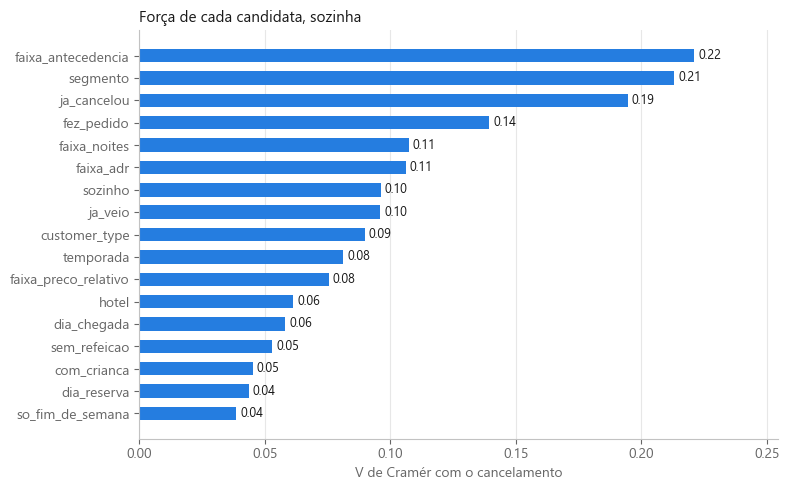

,V_cramer
faixa_antecedencia,0.221
segmento,0.213
ja_cancelou,0.194
fez_pedido,0.139
faixa_noites,0.107
faixa_adr,0.106
sozinho,0.096
ja_veio,0.096
customer_type,0.090
temporada,0.081


In [4]:
candidatas = ['faixa_antecedencia', 'segmento', 'customer_type', 'temporada', 'hotel', 'ja_veio', 'ja_cancelou',
              'fez_pedido', 'sozinho', 'com_crianca', 'sem_refeicao', 'faixa_noites', 'so_fim_de_semana',
              'dia_chegada', 'dia_reserva', 'faixa_adr', 'faixa_preco_relativo']
forca = pd.Series({v: cramer_v(base, v) for v in candidatas}).sort_values()

fig, ax = plt.subplots(figsize=(8, 5))
barras = ax.barh(forca.index, forca.values, color=AZUL, height=0.6)
ax.bar_label(barras, labels=[f'{v:.2f}' for v in forca.values], padding=3, color=TINTA, fontsize=9)
ax.grid(axis='x')
ax.grid(axis='y', visible=False)
ax.set_xlim(0, forca.max() * 1.15)
ax.set_xlabel('V de Cramér com o cancelamento')
ax.set_title('Força de cada candidata, sozinha')
plt.tight_layout()
plt.show()
forca.sort_values(ascending=False).to_frame('V_cramer')

### <code style="color:purple">COMENTÁRIOS:</code>

- A ordem: antecedência (0,22), segmento (0,21), já cancelou (0,19), fez pedido (0,14), noites (0,11), diária (0,11), sozinho e já veio (0,10), tipo de cliente (0,09) e temporada (0,08). Abaixo disso: preço relativo, hotel, dia da chegada, sem refeição, com criança, dia da reserva e só fim de semana.
- **Nenhuma variável é forte sozinha** (todas abaixo de 0,25). O modelo vai depender da combinação, o que é esperado num fenômeno com muitos motivos, como o cancelamento.

## 3. Relações entre as explicativas

### <code style="color:green">Por que olhar</code>

Duas variáveis que dizem a mesma coisa disputam o mesmo efeito no modelo: os coeficientes ficam instáveis e difíceis de interpretar. O mapa abaixo mostra o V de Cramér entre cada par de candidatas. Acima de 0,5, uma delas provavelmente sobra.

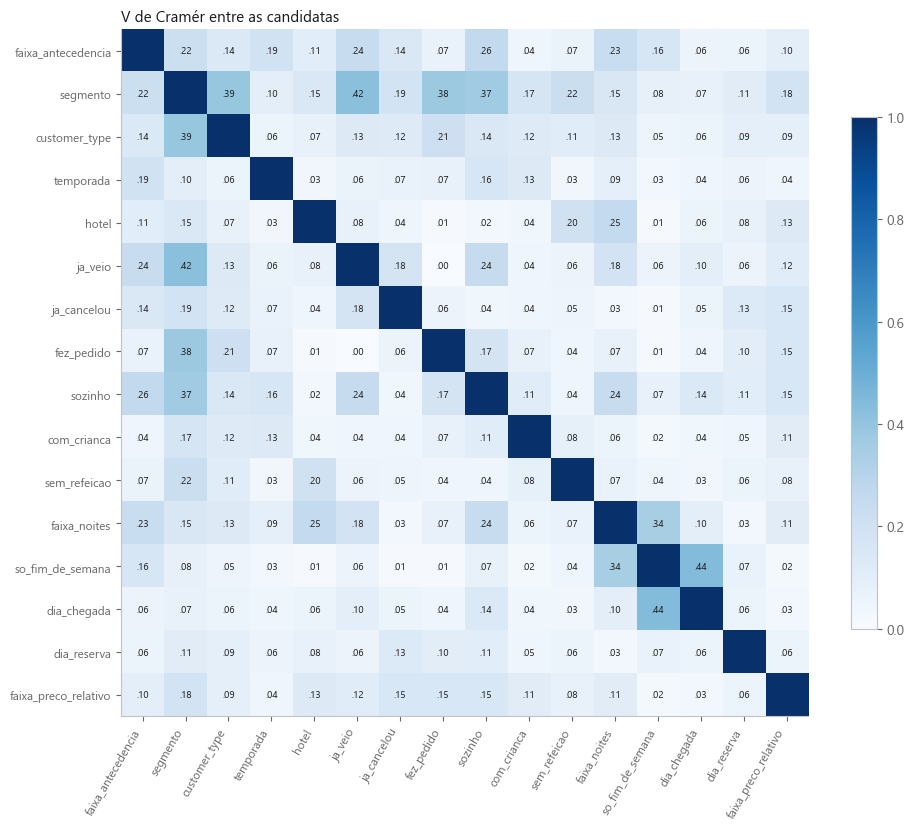

V_cramer
so_fim_de_semana   dia_chegada          0.440
segmento           ja_veio              0.421
                   customer_type        0.392
                   fez_pedido           0.378
                   sozinho              0.365
faixa_noites       so_fim_de_semana     0.341
faixa_antecedencia sozinho              0.260
hotel              faixa_noites         0.254
ja_veio            sozinho              0.244
faixa_antecedencia ja_veio              0.237

In [5]:
pares = [v for v in candidatas if v not in ('faixa_adr',)]
matriz = pd.DataFrame(np.eye(len(pares)), index=pares, columns=pares)
for i, a in enumerate(pares):
    for b in pares[i + 1:]:
        matriz.loc[a, b] = matriz.loc[b, a] = cramer_v(base, a, b)

fig, ax = plt.subplots(figsize=(10, 8.5))
im = ax.imshow(matriz.values, cmap='Blues', vmin=0, vmax=1)
ax.set_xticks(range(len(pares)), pares, rotation=60, ha='right', fontsize=8.5)
ax.set_yticks(range(len(pares)), pares, fontsize=8.5)
ax.grid(False)
for i in range(len(pares)):
    for j in range(len(pares)):
        if i != j:
            v = matriz.values[i, j]
            ax.text(j, i, f'{v:.2f}'.lstrip('0') if v < 1 else '1', ha='center', va='center', fontsize=7,
                    color='white' if v > 0.55 else TINTA)
ax.set_title('V de Cramér entre as candidatas')
fig.colorbar(im, ax=ax, shrink=0.7)
plt.tight_layout()
plt.show()

fortes = (matriz.where(np.triu(np.ones(matriz.shape, dtype=bool), k=1)).stack().sort_values(ascending=False))
fortes.head(10).to_frame('V_cramer')

### <code style="color:purple">COMENTÁRIOS:</code>

- **Nenhum par passa de 0,5:** não há redundância forte entre as candidatas.
- Os maiores pares envolvem o segmento: com já veio (0,42), tipo de cliente (0,39), fez pedido (0,38) e sozinho (0,37). O segmento é o centro das relações: no modelo, ele divide o efeito com essas variáveis, e o efeito de cada uma muda em relação ao que se vê sozinha (seção 4).
- Só fim de semana × dia da chegada (0,44) e noites × só fim de semana (0,34) são esperados: são formas diferentes de medir a mesma estadia. Mais um motivo para usar só o total de noites.

## 4. Confusão e interação

### <code style="color:green">Duas perguntas</code>

- **Confusão:** a diferença entre dois grupos é real ou vem de outra variável? Exemplo: o hotel urbano cancela mais porque é urbano ou porque recebe mais reservas de agência online, que cancelam mais?
- **Interação:** o efeito de uma variável é o mesmo em todos os grupos? Exemplo: a antecedência pesa igual na agência online e nas reservas diretas?

Se houver interação forte, o modelo pode precisar de um termo de interação. Mas cada termo a mais torna o modelo mais difícil de explicar.

segmento,Online TA,Offline TA/TO,Groups,Direct,Corporate
faixa_antecedencia,,,,,
ate_7d,0.092,0.112,0.128,0.080,0.076
8_30d,0.320,0.135,0.244,0.192,0.144
31_90d,0.396,0.177,0.249,0.206,0.278
91_180d,0.445,0.185,0.257,0.189,0.416
mais_180d,0.535,0.198,0.355,0.263,0.115


segmento,Online TA,Offline TA/TO,Groups,Direct,Corporate
faixa_antecedencia,,,,,
ate_7d,8315,2009,640,5253,2699
8_30d,10923,2413,1305,2290,1316
31_90d,16454,5007,2507,2374,731
91_180d,13233,4939,2077,1808,185
mais_180d,7478,4841,3980,856,26


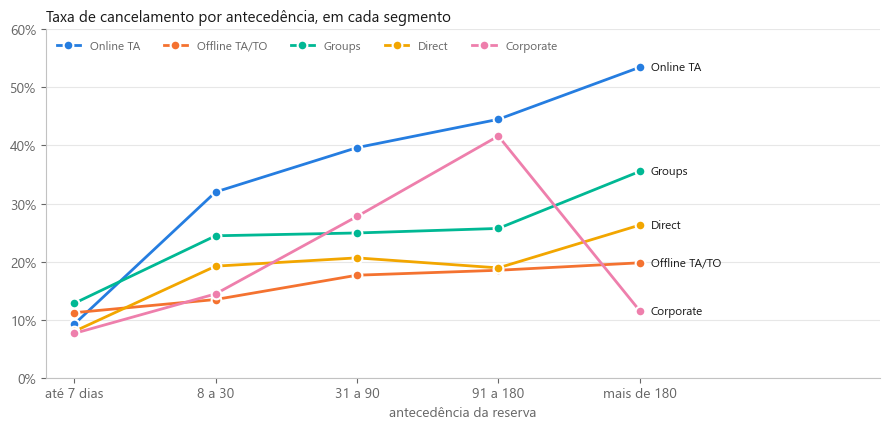

In [6]:
principais = ['Online TA', 'Offline TA/TO', 'Groups', 'Direct', 'Corporate']
sub = base[base['segmento'].isin(principais)]
cruz = sub.pivot_table(index='faixa_antecedencia', columns='segmento', values=Y, aggfunc='mean', observed=True)[principais]
contagem = sub.pivot_table(index='faixa_antecedencia', columns='segmento', values=Y, aggfunc='size', observed=True)[principais]
display(cruz)
display(contagem)

rotulos = ['até 7 dias', '8 a 30', '31 a 90', '91 a 180', 'mais de 180']
fig, ax = plt.subplots(figsize=(9, 4.4))
for cor, seg in zip(SERIES, principais):
    ax.plot(rotulos, cruz[seg], marker='o', color=cor, linewidth=2, markersize=7,
            markeredgecolor='white', markeredgewidth=1.5, label=seg)
    ax.annotate(seg, (len(rotulos) - 1, cruz[seg].iloc[-1]), xytext=(8, 0), textcoords='offset points',
                va='center', color=TINTA, fontsize=8.5)
ax.yaxis.set_major_formatter(pct)
ax.set_ylim(0, 0.6)
ax.set_xlim(-0.2, len(rotulos) - 0.2 + 0.9)
ax.set_xlabel('antecedência da reserva')
ax.set_title('Taxa de cancelamento por antecedência, em cada segmento')
ax.legend(loc='upper left', ncol=5, fontsize=8.5)
plt.tight_layout()
plt.show()

### <code style="color:purple">COMENTÁRIOS:</code>

- **Há interação forte.** Na agência online, a taxa sobe de 9% (até 7 dias) para 54% (mais de 180 dias). Na operadora tradicional (Offline TA/TO), quase não muda: de 11% para 20%. Grupos e reservas diretas ficam no meio (de 13% para 36% e de 8% para 26%).
- Corporate sobe até 42% (91 a 180 dias) e cai para 12% acima de 180 dias, mas com só 26 reservas nessa faixa. Não dá para ler.
- Na última semana, todos os segmentos cancelam pouco (8% a 13%): a reserva de última hora quase não cancela, venha de onde vier.
- **Para o modelo:** um único efeito de antecedência para todos subestimaria o risco da agência online com antecedência longa e superestimaria o da operadora. Vale testar um termo de interação "agência online × antecedência" e comparar pelo AIC.
- **Para a história:** "na agência online, cada mês a mais de antecedência pesa muito mais" é uma frase forte para o slide 3.

In [7]:
print('--- hotel dentro de cada segmento (taxa de cancelamento)')
display(sub.pivot_table(index='segmento', columns='hotel', values=Y, aggfunc='mean').loc[principais])
print('--- mistura de segmentos em cada hotel (% das reservas)')
display(pd.crosstab(sub['hotel'], sub['segmento'], normalize='index')[principais])

print('--- pedido especial dentro de cada segmento (taxa de cancelamento)')
display(sub.pivot_table(index='segmento', columns='fez_pedido', values=Y, aggfunc='mean').loc[principais])
print('--- % de reservas com pedido especial em cada segmento')
sub.groupby('segmento')['fez_pedido'].mean().loc[principais].to_frame('pct_com_pedido')

--- hotel dentro de cada segmento (taxa de cancelamento)


hotel,City Hotel,Resort Hotel
segmento,,
Online TA,0.373,0.351
Offline TA/TO,0.195,0.135
Groups,0.312,0.240
Direct,0.171,0.135
Corporate,0.129,0.146


--- mistura de segmentos em cada hotel (% das reservas)


segmento,Online TA,Offline TA/TO,Groups,Direct,Corporate
hotel,,,,,
City Hotel,0.590,0.181,0.096,0.093,0.041
Resort Hotel,0.466,0.193,0.110,0.171,0.060


--- pedido especial dentro de cada segmento (taxa de cancelamento)


fez_pedido,False,True
segmento,,
Online TA,0.545,0.263
Offline TA/TO,0.203,0.093
Groups,0.330,0.017
Direct,0.172,0.121
Corporate,0.153,0.070


--- % de reservas com pedido especial em cada segmento


,pct_com_pedido
segmento,
Online TA,0.634
Offline TA/TO,0.281
Groups,0.149
Direct,0.391
Corporate,0.194


### <code style="color:purple">COMENTÁRIOS:</code>

- **Hotel:** o urbano cancela mais que o resort em quase todos os segmentos, mas a diferença encolhe: na agência online, 37,3% contra 35,1%. Parte da diferença geral (30,5% contra 24,7%) vem da mistura, porque o urbano recebe mais reservas de agência online (59% contra 47%). No modelo, o efeito do hotel deve ficar menor.
- **Pedido especial:** o efeito se mantém, e fica até mais forte, dentro de cada segmento. Na agência online, 54,5% sem pedido contra 26,3% com pedido; em Groups, 33,0% contra 1,7%. A agência online tem mais pedidos (63% das reservas) e também cancela mais, o que, com tudo misturado, escondia parte do efeito. Um efeito tão forte reforça a dúvida sobre quando o pedido é feito (seção 5).

In [8]:
print('--- temporada dentro de cada hotel (taxa de cancelamento)')
display(base.pivot_table(index='temporada', columns='hotel', values=Y, aggfunc='mean'))
print('--- cliente que já veio, dentro de cada segmento (taxa de cancelamento)')
base[base['segmento'].isin(principais)].pivot_table(index='segmento', columns='ja_veio', values=Y,
                                                    aggfunc=['mean', 'size']).loc[principais]

--- temporada dentro de cada hotel (taxa de cancelamento)


hotel,City Hotel,Resort Hotel
temporada,,
abr_jun,0.315,0.271
jul_ago,0.346,0.321
set_mar,0.279,0.199


--- cliente que já veio, dentro de cada segmento (taxa de cancelamento)


mean         size      
ja_veio       False True   False True 
segmento                              
Online TA     0.370 0.016  55894   509
Offline TA/TO 0.174 0.029  18964   245
Groups        0.284 0.217  10426    83
Direct        0.158 0.056  11829   752
Corporate     0.181 0.054   3227  1730

### <code style="color:purple">COMENTÁRIOS:</code>

- **Temporada × hotel:** a sazonalidade é mais forte no resort (de 19,9% fora da temporada para 32,1% em julho e agosto) que no urbano (de 27,9% para 34,6%). Diferença pequena; não vale um termo de interação.
- **Cliente que já veio:** cancela muito menos em todos os segmentos (na agência online, 1,6% contra 37,0%; nas diretas, 5,6% contra 15,8%). O efeito é consistente, mas o volume é pequeno, exceto no corporativo, onde 1.730 das 4.957 reservas são de quem já veio.

## 5. O pedido especial foi feito na reserva ou depois?

### <code style="color:green">O teste</code>

O efeito do pedido especial é forte demais dentro de todos os segmentos. Se o pedido for registrado **na reserva**, é uma ótima variável. Se puder ser feito **depois**, perto da chegada, ele vaza a resposta: quem vai mesmo se hospedar faz pedidos, e quem desiste não faz.

A base não diz quando o pedido foi feito, mas dá para testar. Se os pedidos se acumulam ao longo da vida da reserva, as reservas que ficaram mais tempo abertas antes de cancelar devem ter mais pedidos. Se o pedido é feito na reserva, o tempo de vida não deve importar.

O tempo de vida é contado da reserva até o cancelamento (para quem cancelou) ou até a chegada (para quem veio). Para não misturar com o efeito da antecedência, comparamos reservas com antecedência parecida.

In [9]:
base['data_status'] = pd.to_datetime(base['reservation_status_date'])
fim = base[['data_status', 'chegada']].min(axis=1)              # cancelamento ou chegada, o que vier primeiro
base['dias_de_vida'] = (fim - base['data_reserva']).dt.days
base['faixa_vida'] = pd.cut(base['dias_de_vida'], [-1, 2, 14, 60, 180, np.inf],
                            labels=['0_2d', '3_14d', '15_60d', '61_180d', 'mais_180d'])

canceladas = base[base['reservation_status'] == 'Canceled']
print('--- canceladas: % com pedido especial, por tempo de vida e faixa de antecedência')
display(canceladas.pivot_table(index='faixa_vida', columns='faixa_antecedencia', values='fez_pedido',
                               aggfunc='mean', observed=True))
display(canceladas.pivot_table(index='faixa_vida', columns='faixa_antecedencia', values='fez_pedido',
                               aggfunc='size', observed=True))

print('--- quem veio: % com pedido especial, por faixa de antecedência')
base[base[Y] == 0].groupby('faixa_antecedencia', observed=True)['fez_pedido'].agg(['mean', 'size'])

--- canceladas: % com pedido especial, por tempo de vida e faixa de antecedência


faixa_antecedencia,ate_7d,8_30d,31_90d,91_180d,mais_180d
faixa_vida,,,,,
0_2d,0.228,0.316,0.243,0.218,0.139
3_14d,0.357,0.440,0.418,0.419,0.439
15_60d,NaN,0.352,0.395,0.390,0.472
61_180d,NaN,NaN,0.447,0.386,0.395
mais_180d,NaN,NaN,NaN,NaN,0.296


faixa_antecedencia,ate_7d,8_30d,31_90d,91_180d,mais_180d
faixa_vida,,,,,
0_2d,"1,200.000","1,684.000","2,221.000","1,368.000",942.000
3_14d,269.000,"2,209.000","2,091.000","1,383.000",693.000
15_60d,NaN,644.000,"3,568.000","1,715.000",851.000
61_180d,NaN,NaN,591.000,"3,057.000","2,192.000"
mais_180d,NaN,NaN,NaN,NaN,"1,844.000"


--- quem veio: % com pedido especial, por faixa de antecedência


,mean,size
faixa_antecedencia,,
ate_7d,0.420,17821
8_30d,0.545,13636
31_90d,0.542,18403
91_180d,0.554,14500
mais_180d,0.518,10587


### <code style="color:purple">COMENTÁRIOS:</code>

- **Não há sinal de que os pedidos se acumulem até a chegada.** Entre as canceladas que ficaram mais de duas semanas abertas, a parcela com pedido fica entre 30% e 47% e não sobe com o tempo de vida. Entre quem veio, ela fica entre 52% e 55% (42% na última semana).
- **Mas quem cancela nos dois primeiros dias quase não tem pedido.** Com mais de 180 dias de antecedência, são 13,9% entre quem cancelou em até 2 dias, contra 43,9% entre quem cancelou de 3 a 14 dias depois. Parte disso pode ser falta de tempo para pedir, e parte pode ser perfil: quem desiste logo pode ter reservado por impulso.
- **Leitura:** o pedido parece ser feito na reserva ou nos primeiros dias. O risco de vazamento é menor do que parecia, mas existe: se o modelo for usado no exato momento da reserva, um pedido feito no dia seguinte ainda não existe.
- **Proposta:** manter `fez_pedido` na lista de testar. Se entrar, o score passa a ser calculado alguns dias depois da reserva, junto com a ligação de confirmação.

## 6. Preço

In [10]:
print('--- diária média por temporada e hotel (mediana)')
display(base.pivot_table(index='temporada', columns='hotel', values='adr', aggfunc='median'))
print('--- correlação de Spearman entre diária, antecedência, noites e hóspedes')
display(base[['adr', 'preco_relativo', 'lead_time', 'noites', 'hospedes']].corr(method='spearman'))
print('--- preço relativo dentro de cada segmento (taxa de cancelamento)')
base[base['segmento'].isin(principais)].pivot_table(index='faixa_preco_relativo', columns='segmento', values=Y,
                                                    aggfunc='mean', observed=True)[principais]

--- diária média por temporada e hotel (mediana)


hotel,City Hotel,Resort Hotel
temporada,,
abr_jun,116.100,81.000
jul_ago,112.500,169.000
set_mar,90.000,55.800


--- correlação de Spearman entre diária, antecedência, noites e hóspedes


,adr,preco_relativo,lead_time,noites,hospedes
adr,1.000,0.582,0.076,0.091,0.405
preco_relativo,0.582,1.000,-0.125,-0.045,0.227
lead_time,0.076,-0.125,1.000,0.401,0.194
noites,0.091,-0.045,0.401,1.000,0.205
hospedes,0.405,0.227,0.194,0.205,1.000


--- preço relativo dentro de cada segmento (taxa de cancelamento)


segmento,Online TA,Offline TA/TO,Groups,Direct,Corporate
faixa_preco_relativo,,,,,
q1_mais_barato,0.246,0.176,0.392,0.185,0.106
q2,0.381,0.162,0.179,0.152,0.141
q3,0.400,0.186,0.237,0.154,0.199
q4,0.383,0.175,0.248,0.157,0.119
q5_mais_caro,0.355,0.147,0.245,0.130,0.133


### <code style="color:purple">COMENTÁRIOS:</code>

- A diária segue a temporada, principalmente no resort: mediana de 169 em julho e agosto, contra 55,80 de setembro a março. No urbano, varia de 90 a 116.
- A diária anda junto com o número de hóspedes (Spearman de 0,41), e a antecedência com o número de noites (0,40). A diária quase não se relaciona com a antecedência (0,08).
- O preço relativo interage com o segmento de um jeito difícil de explicar: na agência online, a reserva mais barata cancela menos (24,6% contra 36% a 40%); em Groups, cancela mais (39,2% contra 18% a 25%). Mais um motivo para deixá-lo fora e usar a própria diária.

## 7. O que mudou em 2017

### <code style="color:green">Mistura ou comportamento?</code>

A taxa de 2017 pode subir por dois motivos: **a mistura mudou** (mais reservas dos grupos que já cancelavam muito) ou **o comportamento mudou** (cada grupo passou a cancelar mais). Para separar os dois, comparamos os mesmos meses (janeiro a agosto) de 2016 e 2017 e calculamos a taxa que 2017 teria com o comportamento de 2016 e a mistura de 2017.

In [11]:
meses = ['January', 'February', 'March', 'April', 'May', 'June', 'July', 'August']
p16 = base[(base['arrival_date_year'] == 2016) & base['arrival_date_month'].isin(meses)]
p17 = base[base['arrival_date_year'] == 2017]

def comparar(var):
    t = pd.DataFrame({
        'mistura_2016': p16[var].value_counts(normalize=True),
        'mistura_2017': p17[var].value_counts(normalize=True),
        'taxa_2016': p16.groupby(var, observed=True)[Y].mean(),
        'taxa_2017': p17.groupby(var, observed=True)[Y].mean(),
    }).fillna(0)
    so_mistura = (t['mistura_2017'] * t['taxa_2016']).sum()
    return t, so_mistura

for var in ['segmento', 'faixa_antecedencia', 'hotel']:
    t, so_mistura = comparar(var)
    print(f'\n--- {var}: taxa 2016 = {p16[Y].mean():.3f} | 2017 só com a mistura nova = {so_mistura:.3f} | 2017 real = {p17[Y].mean():.3f}')
    display(t)


--- segmento: taxa 2016 = 0.262 | 2017 só com a mistura nova = 0.276 | 2017 real = 0.318


,mistura_2016,mistura_2017,taxa_2016,taxa_2017
segmento,,,,
Corporate,0.052,0.038,0.136,0.153
Direct,0.120,0.126,0.145,0.153
Groups,0.067,0.084,0.252,0.204
Offline TA/TO,0.202,0.124,0.162,0.169
Online TA,0.550,0.619,0.339,0.408
Outros,0.008,0.009,0.143,0.179



--- faixa_antecedencia: taxa 2016 = 0.262 | 2017 só com a mistura nova = 0.270 | 2017 real = 0.318


,mistura_2016,mistura_2017,taxa_2016,taxa_2017
faixa_antecedencia,,,,
ate_7d,0.214,0.158,0.096,0.083
8_30d,0.168,0.169,0.281,0.285
31_90d,0.256,0.230,0.333,0.354
91_180d,0.238,0.248,0.316,0.371
mais_180d,0.124,0.195,0.272,0.426



--- hotel: taxa 2016 = 0.262 | 2017 só com a mistura nova = 0.262 | 2017 real = 0.318


,mistura_2016,mistura_2017,taxa_2016,taxa_2017
hotel,,,,
City Hotel,0.641,0.648,0.278,0.332
Resort Hotel,0.359,0.352,0.234,0.291


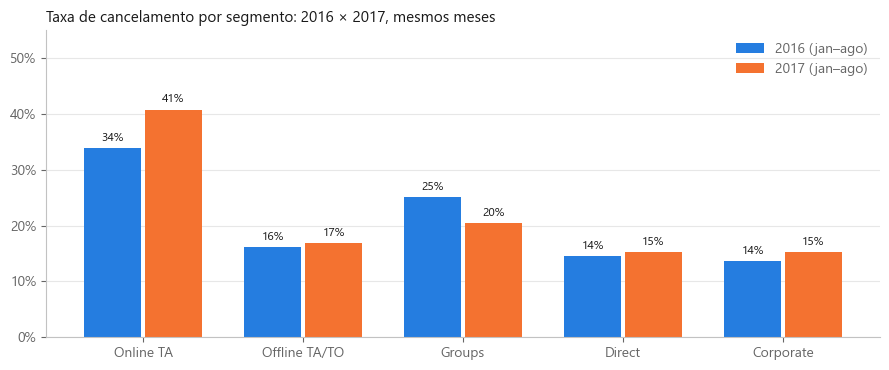

In [12]:
t, _ = comparar('segmento')
t = t.loc[principais]
fig, ax = plt.subplots(figsize=(9, 3.8))
x = np.arange(len(t))
largura = 0.36
for desloc, col, cor, nome in [(-largura / 2 - 0.01, 'taxa_2016', SERIES[0], '2016 (jan–ago)'),
                               (largura / 2 + 0.01, 'taxa_2017', SERIES[1], '2017 (jan–ago)')]:
    barras = ax.bar(x + desloc, t[col], largura, color=cor, label=nome)
    ax.bar_label(barras, labels=[f'{v:.0%}' for v in t[col]], padding=3, color=TINTA, fontsize=8.5)
ax.set_xticks(x, t.index)
ax.yaxis.set_major_formatter(pct)
ax.set_ylim(0, 0.55)
ax.set_title('Taxa de cancelamento por segmento: 2016 × 2017, mesmos meses')
ax.legend(loc='upper right')
plt.tight_layout()
plt.show()

### <code style="color:purple">COMENTÁRIOS:</code>

- **A maior parte da alta é comportamento, não mistura.** Nos mesmos meses, 2016 teve 26,2% e 2017, 31,8%. Com o comportamento de 2016 e a mistura de segmentos de 2017, a taxa seria 27,6%. A mistura explica 1,4 dos 5,6 pontos, cerca de um quarto; o resto vem de cada grupo cancelar mais.
- **A mudança se concentra onde o risco já era alto.** A agência online passou de 55% para 62% das reservas, e sua taxa, de 33,9% para 40,8%. As reservas com mais de 180 dias de antecedência passaram de 12% para 20% da base, e sua taxa saltou de 27,2% para 42,6%.
- A operadora tradicional encolheu (de 20% para 12% das reservas) e quase não mudou de taxa. Groups foi o único segmento a cancelar menos (de 25,2% para 20,4%). Os dois hotéis subiram cerca de 5 pontos, com a mesma mistura.
- **Para o modelo:** como os grupos mais arriscados ficaram ainda mais arriscados, a ordem das reservas deve se manter, o que é bom para a lista de ligação. Já as probabilidades devem sair baixas para 2017, o que atrapalha o uso para overbooking. É preciso conferir a calibração.

## 8. Multicolinearidade: VIF

### <code style="color:green">Como ler</code>

O VIF (fator de inflação da variância) mede o quanto cada coluna do modelo é explicada pelas outras. Perto de 1, ela traz informação própria; acima de 5, está repetindo as outras e o coeficiente fica instável. Calculamos com as candidatas em dummies, deixando de fora uma categoria de referência em cada variável.

In [13]:
conjunto = ['faixa_antecedencia', 'segmento', 'customer_type', 'temporada', 'hotel', 'ja_veio', 'ja_cancelou',
            'fez_pedido', 'sozinho', 'com_crianca', 'sem_refeicao', 'faixa_noites', 'so_fim_de_semana']
X = pd.get_dummies(base[conjunto].astype(str), drop_first=True, dtype=float)
X['adr_padronizada'] = (base['adr'] - base['adr'].mean()) / base['adr'].std()
X.insert(0, 'constante', 1.0)
vif = pd.Series([variance_inflation_factor(X.values, i) for i in range(X.shape[1])], index=X.columns).drop('constante')
vif.sort_values(ascending=False).to_frame('VIF').head(12)

,VIF
faixa_noites_2_3,38.274
faixa_noites_4_7,35.448
faixa_noites_1,24.233
faixa_noites_mais_7,8.351
segmento_Online TA,8.226
customer_type_Transient-Party,6.756
customer_type_Transient,6.573
segmento_Offline TA/TO,5.113
segmento_Direct,3.823
segmento_Groups,3.761


### <code style="color:purple">COMENTÁRIOS:</code>

- Com a referência alfabética, as faixas de noites passam de 24 de VIF, e alguns níveis do segmento e do tipo de cliente ficam entre 5 e 8.

### <code style="color:green">A mesma conta, com a categoria mais frequente como referência</code>

O `drop_first` deixa de fora a primeira categoria em ordem alfabética. Quando ela é pequena (por exemplo, as 715 reservas com zero noites), as outras dummies quase somam 1 e repetem a constante, o que infla o VIF sem que as variáveis sejam de fato redundantes. Trocando a referência pela categoria mais frequente:

In [14]:
partes, referencias = [], {}
for v in conjunto:
    s = base[v].astype(str)
    referencias[v] = s.value_counts().idxmax()
    partes.append(pd.get_dummies(s, prefix=v, dtype=float).drop(columns=f'{v}_{referencias[v]}'))
X2 = pd.concat(partes, axis=1)
X2['adr_padronizada'] = X['adr_padronizada']
X2.insert(0, 'constante', 1.0)
vif2 = pd.Series([variance_inflation_factor(X2.values, i) for i in range(X2.shape[1])], index=X2.columns).drop('constante')
display(pd.Series(referencias, name='categoria de referência').to_frame())
vif2.sort_values(ascending=False).to_frame('VIF').head(12)

,categoria de referência
faixa_antecedencia,31_90d
segmento,Online TA
customer_type,Transient
temporada,set_mar
hotel,City Hotel
ja_veio,False
ja_cancelou,False
fez_pedido,False
sozinho,False
com_crianca,False


,VIF
segmento_Groups,2.016
customer_type_Transient-Party,1.887
faixa_antecedencia_ate_7d,1.806
adr_padronizada,1.737
segmento_Offline TA/TO,1.555
temporada_jul_ago,1.536
faixa_antecedencia_mais_180d,1.521
segmento_Corporate,1.494
faixa_antecedencia_91_180d,1.493
faixa_noites_1,1.487


### <code style="color:purple">COMENTÁRIOS:</code>

- Com a categoria mais frequente como referência, **todos os VIF ficam abaixo de 2,1**. Não há multicolinearidade entre as candidatas: os valores altos acima vinham de referências pequenas (as 715 reservas com zero noites e os 3.530 contratos).
- **Regra para o modelo:** usar como referência a categoria mais frequente (ou a mais natural para o negócio) e juntar categorias pequenas antes de criar as dummies. Nas noites, juntar "0" com "1".

## 9. O que muda para o modelo

### <code style="color:purple">Conclusões e próximos passos</code>

1. **Variáveis novas:** só o **total de noites em faixas** vale a pena, com escada clara. Dia da semana da chegada e da reserva, só fim de semana e preço relativo ficam fora, por serem fracos ou difíceis de explicar.
2. **Interação a testar:** **agência online × antecedência**. É a relação mais forte da base e conversa com a regra simples do notebook 02.
3. **Confusão:** o efeito do hotel deve encolher no modelo, porque parte dele é a mistura de segmentos. As razões de chances do hotel precisam ser lidas com isso em mente.
4. **Pedido especial:** sem sinal de acúmulo até a chegada, mas com sinal nos dois primeiros dias. Continua em teste; se entrar, o score é calculado alguns dias depois da reserva.
5. **Sem multicolinearidade,** desde que a referência de cada variável seja a categoria mais frequente e as categorias pequenas sejam juntadas.
6. **2017:** a alta é sobretudo comportamento, concentrada na agência online com antecedência longa. A ordem das reservas deve se manter; a calibração, não.
7. **Dicionário de dados:** atualizado com o total de noites em faixas e com as variáveis derivadas que ficaram fora.